In [21]:
%load_ext autoreload
%autoreload 2

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import catboost as cb
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from utils import to_category, fit_categories, make_cox_df, make_aft_df, tune, Model

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
MODELS_DIR = "./models"
DATA_DIR = "./data"

In [2]:
FEATURES = [
    "model",
    "environment",
    "is_refurbished",
    "initial_battery_cycles",
    "firmware_major",
    "maintenance_interval_h",
    "operator_experience_yrs",
    "daily_utilization_h",
    "avg_flight_min",
    "avg_payload_kg",
    "payload_ratio",
    "mean_temp_c",
    "avg_humidity_pct",
    "avg_wind_ms",
    "hard_landings_per_100h",
    "mean_vibration_g",
]

CAT_FEATURES = ['model', 'environment', 'is_refurbished', 'firmware_major']
DROP_FEATURES = ["drone_id", "commission_date", "duration_h", "event", "failure_mode"]

In [3]:
df = pd.read_csv("data/drone_survival.csv")

In [4]:
df.head()

,drone_id,model,environment,commission_date,is_refurbished,initial_battery_cycles,firmware_major,maintenance_interval_h,operator_experience_yrs,daily_utilization_h,...,avg_payload_kg,payload_ratio,mean_temp_c,avg_humidity_pct,avg_wind_ms,hard_landings_per_100h,mean_vibration_g,duration_h,event,failure_mode
0,DR-000000,hexa_heavy,urban,2024-08-12,False,22,5,50,3.93,3.42,...,3.886,0.389,-0.1,65.9,4.68,2.60,0.507,224.02,0,censored
1,DR-000001,quad_heavy,coastal,2025-01-06,False,25,4,50,3.99,1.06,...,4.166,0.833,23.7,65.2,5.16,2.72,0.678,380.54,0,censored
2,DR-000002,fixed_wing_vtol,coastal,2024-08-10,False,2,5,50,3.30,1.66,...,2.278,0.759,23.9,73.8,3.70,1.89,0.424,11.57,1,electronics
3,DR-000003,hexa_heavy,urban,2024-11-05,False,5,3,25,3.34,2.48,...,7.129,0.713,11.2,57.8,3.78,1.00,0.440,1044.08,0,censored
4,DR-000004,quad_light,urban,2025-04-25,False,8,4,200,2.11,1.63,...,0.335,0.335,19.2,54.7,6.20,1.63,0.367,63.67,1,crash


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   drone_id                 5000 non-null   str    
 1   model                    5000 non-null   str    
 2   environment              5000 non-null   str    
 3   commission_date          5000 non-null   str    
 4   is_refurbished           5000 non-null   bool   
 5   initial_battery_cycles   5000 non-null   int64  
 6   firmware_major           5000 non-null   int64  
 7   maintenance_interval_h   5000 non-null   int64  
 8   operator_experience_yrs  5000 non-null   float64
 9   daily_utilization_h      5000 non-null   float64
 10  avg_flight_min           5000 non-null   float64
 11  avg_payload_kg           5000 non-null   float64
 12  payload_ratio            5000 non-null   float64
 13  mean_temp_c              5000 non-null   float64
 14  avg_humidity_pct         5000 non-n

In [6]:
df["commission_date"] = pd.to_datetime(df["commission_date"])

t_val, t_test = df["commission_date"].quantile([0.70, 0.80])

train = df[df["commission_date"] < t_val]
val   = df[(df["commission_date"] >= t_val) & (df["commission_date"] < t_test)]
test  = df[df["commission_date"] >= t_test]

print(len(train) / len(df), len(val) / len(df), len(test) / len(df))
print(train["event"].mean(), val["event"].mean(), test["event"].mean())

0.6998 0.1 0.2002
0.6630465847384968 0.546 0.44755244755244755


In [7]:
df = to_category(df, CAT_FEATURES)
cats = fit_categories(train, CAT_FEATURES)

In [8]:
X_train, y_train = make_cox_df(train, FEATURES, cats)
X_val, y_val = make_cox_df(val, FEATURES, cats)
X_test, y_test = make_cox_df(test, FEATURES, cats)

In [9]:
X_train.head()

,model,environment,is_refurbished,initial_battery_cycles,firmware_major,maintenance_interval_h,operator_experience_yrs,daily_utilization_h,avg_flight_min,avg_payload_kg,payload_ratio,mean_temp_c,avg_humidity_pct,avg_wind_ms,hard_landings_per_100h,mean_vibration_g
0,hexa_heavy,urban,False,22,5,50,3.93,3.42,39.3,3.886,0.389,-0.1,65.9,4.68,2.60,0.507
1,quad_heavy,coastal,False,25,4,50,3.99,1.06,36.1,4.166,0.833,23.7,65.2,5.16,2.72,0.678
2,fixed_wing_vtol,coastal,False,2,5,50,3.30,1.66,53.1,2.278,0.759,23.9,73.8,3.70,1.89,0.424
3,hexa_heavy,urban,False,5,3,25,3.34,2.48,33.6,7.129,0.713,11.2,57.8,3.78,1.00,0.440
6,hexa_heavy,coastal,False,24,3,50,1.40,3.33,40.9,5.827,0.583,19.2,70.5,4.90,1.17,0.624


In [10]:
best_cox = tune("cox", train, val, 1, FEATURES, CAT_FEATURES)
best_aft = tune("aft", train, val, 1, FEATURES, CAT_FEATURES)

[I 2026-11-15 10:50:35,435] A new study created in memory with name: no-name-991dff09-295d-4beb-a4c6-c4bdac03b751
[I 2026-11-15 10:50:35,627] Trial 0 finished with value: 0.12492833551332913 and parameters: {'max_depth': 3, 'eta': 0.13732181501427546, 'min_child_weight': 12.057126287443763, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'reg_lambda': 0.22853255256339203}. Best is trial 0 with value: 0.12492833551332913.
[I 2026-11-15 10:50:35,808] A new study created in memory with name: no-name-476bb38b-0bbe-478d-b584-1404a8794591
[I 2026-11-15 10:50:36,178] Trial 0 finished with value: 0.14507037017079882 and parameters: {'max_depth': 3, 'eta': 0.13732181501427546, 'min_child_weight': 12.057126287443763, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.7468055921327309, 'reg_lambda': 0.22853255256339203, 'aft_loss_distribution_scale': 0.22193603920198923}. Best is trial 0 with value: 0.14507037017079882.


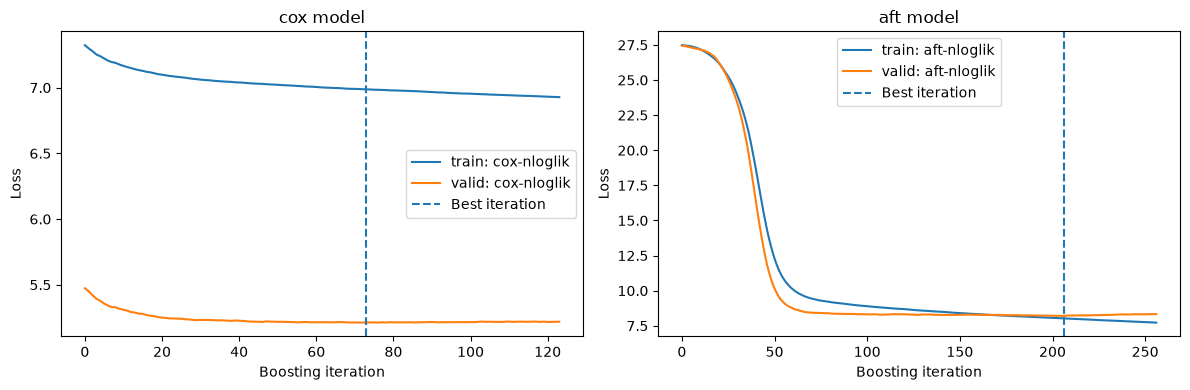

In [17]:
models = {"cox": best_cox, "aft": best_aft}

fig, axes = plt.subplots(1, len(models), figsize=(12, 4))

for ax, (name, model) in zip(axes, models.items()):
    for split, metrics in model.history.items():
        for metric, values in metrics.items():
            ax.plot(values, label=f"{split}: {metric}")

    ax.axvline(model.booster.best_iteration, linestyle="--", label="Best iteration")
    ax.set_title(f"{name} model")
    ax.set_xlabel("Boosting iteration")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [22]:
os.makedirs(MODELS_DIR, exist_ok=True)

best_cox.save("./models/best_cox.json")
best_aft.save("./models/best_aft.json")

best_cox = Model.load("./models/best_cox.json")
best_aft = Model.load("./models/best_aft.json")

TIMES = np.quantile(train["duration_h"], np.linspace(0.1, 0.9, 9))
S_cox = best_cox.survival(test, TIMES)
S_aft = best_aft.survival(test, TIMES)